# 🧫 Hands-On Minggu ke-8: Siklus Sel dan Mitosis
## [VERSI MAHASISWA]

Topik ini mengikuti silabus minggu ke-8: **Siklus sel dan mitosis** dengan fokus fase G1, S, G2, M, checkpoint, dan analisis sederhana populasi sel. [file:1]

Setiap mahasiswa memperoleh parameter tugas yang **unik berbasis NIM**, sehingga dataset kasus, durasi fase, dan skenario checkpoint berbeda antar mahasiswa. [file:1]

## Tujuan
- Memodelkan durasi fase siklus sel secara komputasional.
- Menghitung distribusi proporsi sel pada fase G1/S/G2/M.
- Mensimulasikan pertumbuhan populasi sel sederhana.
- Menganalisis dampak checkpoint delay terhadap dinamika populasi sel.

Konsep ini selaras dengan topik minggu ke-8 tentang fase G1, S, G2, M, mitosis, dan checkpoint siklus sel. [file:1]

In [ ]:
# Jalankan cell ini terlebih dahulu
import hashlib
import math
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid')

PHASES = ['G1', 'S', 'G2', 'M']
BASE_DURATIONS = {
    'G1': [8, 9, 10, 11, 12, 13, 14, 15],
    'S' : [6, 7, 8, 9, 10],
    'G2': [3, 4, 5, 6],
    'M' : [1, 2, 3]
}
GROWTH_FACTORS = [1.70, 1.75, 1.80, 1.85, 1.90, 1.95, 2.00]
INITIAL_CELLS = [2, 3, 4, 5, 6, 8, 10]
CHECKPOINT_TYPES = ['normal', 'g1_delay', 's_delay', 'g2_delay', 'm_delay']


def get_student_case(nim_str):
    h = int(hashlib.md5(nim_str.encode()).hexdigest(), 16)
    g1 = BASE_DURATIONS['G1'][h % len(BASE_DURATIONS['G1'])]
    s  = BASE_DURATIONS['S'][(h // 10) % len(BASE_DURATIONS['S'])]
    g2 = BASE_DURATIONS['G2'][(h // 100) % len(BASE_DURATIONS['G2'])]
    m  = BASE_DURATIONS['M'][(h // 1000) % len(BASE_DURATIONS['M'])]
    growth = GROWTH_FACTORS[(h // 10000) % len(GROWTH_FACTORS)]
    initial = INITIAL_CELLS[(h // 100000) % len(INITIAL_CELLS)]
    checkpoint = CHECKPOINT_TYPES[(h // 1000000) % len(CHECKPOINT_TYPES)]

    durations = {'G1': g1, 'S': s, 'G2': g2, 'M': m}

    # checkpoint-specific perturbation
    perturbed = durations.copy()
    if checkpoint == 'g1_delay':
        perturbed['G1'] += 2
    elif checkpoint == 's_delay':
        perturbed['S'] += 2
    elif checkpoint == 'g2_delay':
        perturbed['G2'] += 2
    elif checkpoint == 'm_delay':
        perturbed['M'] += 1

    return {
        'nim': nim_str,
        'durations_normal': durations,
        'durations_checkpoint': perturbed,
        'growth_factor': growth,
        'initial_cells': initial,
        'checkpoint_type': checkpoint,
        'observation_hours': 72,
    }

print('✅ Setup berhasil dimuat.')
print('Topik hands-on: Siklus sel dan mitosis')


✅ Setup berhasil dimuat.
Topik hands-on: Siklus sel dan mitosis


## Input NIM
Isi NIM Anda pada cell berikut. Parameter tugas akan otomatis dibuat dari NIM Anda.

In [ ]:
# ==================================================
# INPUT NIM DI SINI
# ==================================================
NIM = '18223049'   # Ganti dengan NIM Anda
# ==================================================

case = get_student_case(NIM)
print('='*60)
print(f"NIM                : {case['nim']}")
print(f"Durasi fase normal : {case['durations_normal']}")
print(f"Initial cells      : {case['initial_cells']}")
print(f"Growth factor      : {case['growth_factor']}")
print(f"Checkpoint case    : {case['checkpoint_type']}")
print('='*60)


NIM                : 18223049
Durasi fase normal : {'G1': 11, 'S': 9, 'G2': 5, 'M': 1}
Initial cells      : 5
Growth factor      : 1.8
Checkpoint case    : m_delay


## Tugas 1 — Menghitung Total Durasi Siklus Sel
Implementasikan fungsi untuk menghitung total durasi siklus sel dari durasi fase normal.

**Output yang diharapkan:**
- total durasi (jam)
- persentase kontribusi tiap fase terhadap satu siklus

In [ ]:
def hitung_total_durasi(durations):
    total = sum(durations.values())
    persentase = {fase: round((dur / total) * 100, 2) for fase, dur in durations.items()}

    print(f"Total durasi siklus sel : {total} jam")
    print("Kontribusi tiap fase    :")
    for fase, pct in persentase.items():
        print(f"  {fase}: {durations[fase]} jam ({pct}%)")

    return {'total_jam': total, 'persentase': persentase}

hasil_total = hitung_total_durasi(case['durations_normal'])

Total durasi siklus sel : 26 jam
Kontribusi tiap fase    :
  G1: 11 jam (42.31%)
  S: 9 jam (34.62%)
  G2: 5 jam (19.23%)
  M: 1 jam (3.85%)


## Tugas 2 — Distribusi Proporsi Sel per Fase
Asumsikan bahwa proporsi sel yang teramati pada suatu populasi sebanding dengan lama waktu yang dihabiskan pada tiap fase.

Implementasikan fungsi yang menghitung proporsi G1, S, G2, dan M dari satu siklus sel.

In [ ]:
def proporsi_fase(durations):
    total = sum(durations.values())
    proporsi = {fase: round(dur / total, 4) for fase, dur in durations.items()}

    print("Proporsi sel per fase:")
    for fase, prop in proporsi.items():
        print(f"  {fase}: {prop:.4f} ({prop*100:.2f}%)")

    return proporsi

proporsi = proporsi_fase(case['durations_normal'])

Proporsi sel per fase:
  G1: 0.4231 (42.31%)
  S: 0.3462 (34.62%)
  G2: 0.1923 (19.23%)
  M: 0.0385 (3.85%)


## Tugas 3 — Simulasi Pertumbuhan Populasi Sel
Gunakan parameter `initial_cells`, `growth_factor`, dan `observation_hours`.

Buat fungsi untuk mensimulasikan jumlah sel setiap satu siklus penuh. Untuk penyederhanaan, gunakan model diskrit: setiap satu siklus selesai, jumlah sel dikalikan `growth_factor`.

**Output:** tabel waktu vs jumlah sel.

In [ ]:
def simulasi_populasi(initial_cells, cycle_hours, growth_factor, observation_hours):
    records = []
    jumlah_sel = initial_cells
    waktu = 0

    records.append({'Waktu (jam)': waktu, 'Jumlah Sel': jumlah_sel, 'Siklus ke-': 0})

    siklus = 1
    while waktu + cycle_hours <= observation_hours:
        waktu += cycle_hours
        jumlah_sel = round(jumlah_sel * growth_factor, 2)
        records.append({'Waktu (jam)': waktu, 'Jumlah Sel': jumlah_sel, 'Siklus ke-': siklus})
        siklus += 1

    return pd.DataFrame(records)

sim_df = simulasi_populasi(
    case['initial_cells'],
    sum(case['durations_normal'].values()),
    case['growth_factor'],
    case['observation_hours']
)
sim_df

,Waktu (jam),Jumlah Sel,Siklus ke-
0,0,5.0,0
1,26,9.0,1
2,52,16.2,2


## Tugas 4 — Visualisasi
Buat dua visualisasi:
1. Bar chart proporsi sel per fase.
2. Line chart pertumbuhan populasi sel terhadap waktu.

Gunakan `matplotlib`. Simpan grafik sebagai variabel figure atau tampilkan langsung.

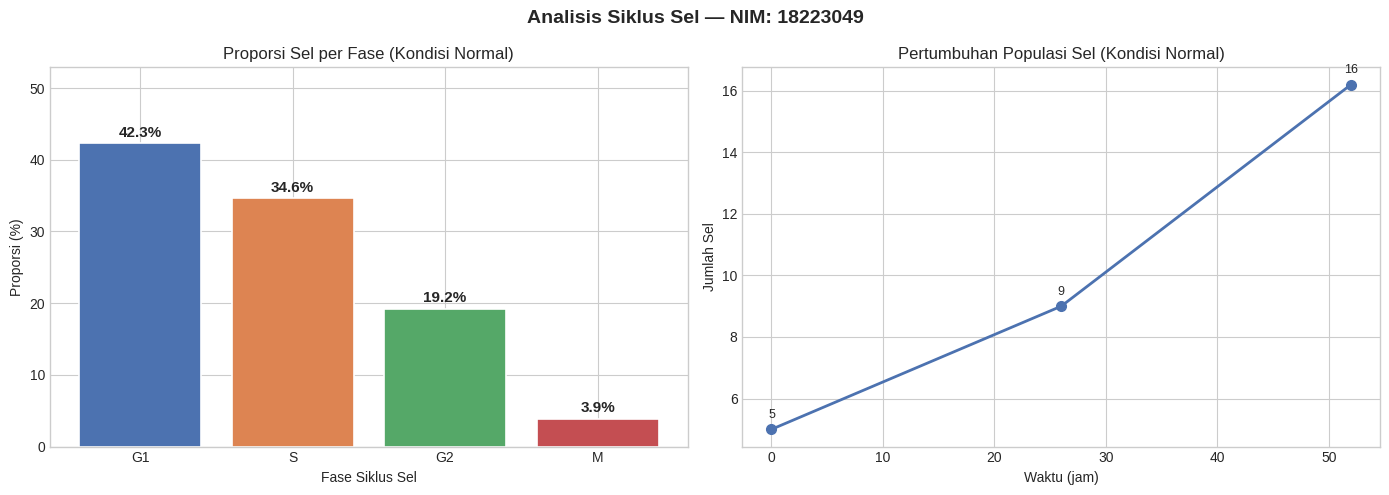

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle(f'Analisis Siklus Sel — NIM: {NIM}', fontsize=14, fontweight='bold')

# Bar chart proporsi sel per fase
ax1 = axes[0]
fases = list(proporsi.keys())
props = [v * 100 for v in proporsi.values()]
colors = ['#4C72B0', '#DD8452', '#55A868', '#C44E52']

bars = ax1.bar(fases, props, color=colors, edgecolor='white', linewidth=1.2)
ax1.set_title('Proporsi Sel per Fase (Kondisi Normal)')
ax1.set_xlabel('Fase Siklus Sel')
ax1.set_ylabel('Proporsi (%)')
ax1.set_ylim(0, max(props) * 1.25)

for bar, val in zip(bars, props):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
             f'{val:.1f}%', ha='center', va='bottom', fontsize=11, fontweight='bold')

# Line chart pertumbuhan populasi
ax2 = axes[1]
ax2.plot(sim_df['Waktu (jam)'], sim_df['Jumlah Sel'],
         marker='o', color='#4C72B0', linewidth=2, markersize=7)
ax2.set_title('Pertumbuhan Populasi Sel (Kondisi Normal)')
ax2.set_xlabel('Waktu (jam)')
ax2.set_ylabel('Jumlah Sel')

for _, row in sim_df.iterrows():
    ax2.annotate(f"{row['Jumlah Sel']:.0f}",
                 (row['Waktu (jam)'], row['Jumlah Sel']),
                 textcoords="offset points", xytext=(0, 8), ha='center', fontsize=9)

plt.tight_layout()
plt.show()

## Tugas 5 — Analisis Checkpoint
Bandingkan kondisi normal dengan kondisi checkpoint delay dari `case['durations_checkpoint']`.

Lakukan:
- Hitung total durasi baru
- Hitung proporsi fase baru
- Simulasikan kembali pertumbuhan populasi
- Bandingkan hasil normal vs checkpoint

Tuliskan interpretasi singkat: checkpoint mana yang terganggu dan apa implikasinya terhadap pertumbuhan populasi.

ANALISIS CHECKPOINT

[NORMAL]
Total durasi siklus sel : 26 jam
Kontribusi tiap fase    :
  G1: 11 jam (42.31%)
  S: 9 jam (34.62%)
  G2: 5 jam (19.23%)
  M: 1 jam (3.85%)
Proporsi sel per fase:
  G1: 0.4231 (42.31%)
  S: 0.3462 (34.62%)
  G2: 0.1923 (19.23%)
  M: 0.0385 (3.85%)

[CHECKPOINT: M_DELAY]
Durasi checkpoint  : {'G1': 11, 'S': 9, 'G2': 5, 'M': 2}
Total durasi siklus sel : 27 jam
Kontribusi tiap fase    :
  G1: 11 jam (40.74%)
  S: 9 jam (33.33%)
  G2: 5 jam (18.52%)
  M: 2 jam (7.41%)
Proporsi sel per fase:
  G1: 0.4074 (40.74%)
  S: 0.3333 (33.33%)
  G2: 0.1852 (18.52%)
  M: 0.0741 (7.41%)

--- PERBANDINGAN HASIL ---
Parameter                            Normal   Checkpoint
-------------------------------------------------------
Total durasi siklus (jam)                26           27
Siklus selesai dalam 72 jam               2            2
Jumlah sel akhir                       16.2         16.2


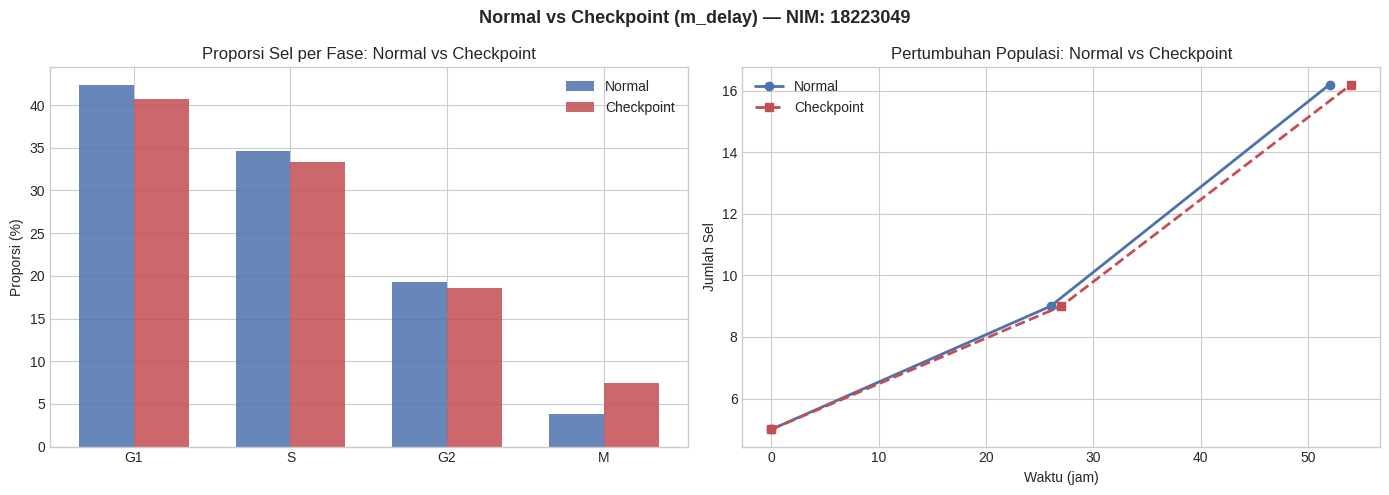

In [ ]:
print("=" * 60)
print("ANALISIS CHECKPOINT")
print("=" * 60)

# Kondisi normal
print("\n[NORMAL]")
hasil_normal = hitung_total_durasi(case['durations_normal'])
proporsi_normal = proporsi_fase(case['durations_normal'])
cycle_normal = hasil_normal['total_jam']

# Kondisi checkpoint — gunakan key 'checkpoint_type'
print(f"\n[CHECKPOINT: {case['checkpoint_type'].upper()}]")
print(f"Durasi checkpoint  : {case['durations_checkpoint']}")
hasil_cp = hitung_total_durasi(case['durations_checkpoint'])
proporsi_cp = proporsi_fase(case['durations_checkpoint'])
cycle_cp = hasil_cp['total_jam']

# Simulasi populasi checkpoint
sim_df_cp = simulasi_populasi(
    case['initial_cells'],
    cycle_cp,
    case['growth_factor'],
    case['observation_hours']
)

# Tabel perbandingan
sel_akhir_normal = sim_df['Jumlah Sel'].iloc[-1]
sel_akhir_cp = sim_df_cp['Jumlah Sel'].iloc[-1]

print("\n--- PERBANDINGAN HASIL ---")
print(f"{'Parameter':<30} {'Normal':>12} {'Checkpoint':>12}")
print("-" * 55)
print(f"{'Total durasi siklus (jam)':<30} {cycle_normal:>12} {cycle_cp:>12}")
print(f"{'Siklus selesai dalam 72 jam':<30} {len(sim_df)-1:>12} {len(sim_df_cp)-1:>12}")
print(f"{'Jumlah sel akhir':<30} {sel_akhir_normal:>12.1f} {sel_akhir_cp:>12.1f}")

# Visualisasi perbandingan
PHASES = ['G1', 'S', 'G2', 'M']
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle(f"Normal vs Checkpoint ({case['checkpoint_type']}) — NIM: {NIM}",
             fontsize=13, fontweight='bold')

# Bar chart proporsi: Normal vs Checkpoint
ax1 = axes[0]
x = range(len(PHASES))
w = 0.35
vals_n = [proporsi_normal[p] * 100 for p in PHASES]
vals_c = [proporsi_cp[p] * 100 for p in PHASES]

ax1.bar([i - w/2 for i in x], vals_n, width=w, label='Normal', color='#4C72B0', alpha=0.85)
ax1.bar([i + w/2 for i in x], vals_c, width=w, label='Checkpoint', color='#C44E52', alpha=0.85)
ax1.set_xticks(list(x))
ax1.set_xticklabels(PHASES)
ax1.set_title('Proporsi Sel per Fase: Normal vs Checkpoint')
ax1.set_ylabel('Proporsi (%)')
ax1.legend()

# Line chart pertumbuhan: Normal vs Checkpoint
ax2 = axes[1]
ax2.plot(sim_df['Waktu (jam)'], sim_df['Jumlah Sel'],
         marker='o', label='Normal', color='#4C72B0', linewidth=2)
ax2.plot(sim_df_cp['Waktu (jam)'], sim_df_cp['Jumlah Sel'],
         marker='s', label='Checkpoint', color='#C44E52', linewidth=2, linestyle='--')
ax2.set_title('Pertumbuhan Populasi: Normal vs Checkpoint')
ax2.set_xlabel('Waktu (jam)')
ax2.set_ylabel('Jumlah Sel')
ax2.legend()

plt.tight_layout()
plt.show()

Berdasarkan data checkpoint_type = m_delay, checkpoint yang terganggu adalah M-phase checkpoint (Spindle Assembly Checkpoint). Pada kondisi ini fase M mengalami penundaan dari 1 jam menjadi 2 jam, sehingga total durasi satu siklus sel meningkat dari 26 jam menjadi 27 jam. Artinya, sel membutuhkan waktu lebih lama sebelum berhasil menyelesaikan proses mitosis.

Berdasarkan grafik proporsi fase sel, terlihat bahwa proporsi sel di fase M meningkat hampir dua kali lipat, sekitar 3,9% → 7,4%. Hal ini menunjukkan banyak sel tertahan di fase mitosis karena checkpoint belum memberikan izin untuk melanjutkan ke anafase. Akibat total siklus menjadi lebih panjang, proporsi fase lain (G1, S, dan G2) sedikit menurun secara relatif, bukan karena jumlah sel berkurang, tetapi karena waktu yang dihabiskan di fase M menjadi lebih lama.

Berdasarkan kurva kondisi checkpoint meningkat dengan pola yang sama seperti kondisi normal, tetapi sedikit tertinggal. Setiap pembelahan membutuhkan tambahan waktu 1 jam, sehingga dalam periode observasi kedua kondisi menghasilkan jumlah sel akhir yang hampir sama ~16 sel, namun kondisi dengan gangguan checkpoint mencapainya lebih lambat. Dengan kata lain, laju pertumbuhan populasi menurun karena siklus sel memanjang.

Dari sisi biologis, spindle assembly checkpoint berfungsi memastikan seluruh kromosom telah terikat dengan benar pada benang spindel sebelum pembelahan berlangsung. Delay ringan seperti pada simulasi ini masih bersifat protektif karena mencegah kesalahan pembagian kromosom. Namun jika gangguan berlangsung terlalu lama, misalnya akibat kelainan protein regulator checkpoint, sel dapat mengalami mitotic arrest berkepanjangan yang berujung pada apoptosis.

## Refleksi
Jawab singkat dalam Markdown:

**1. Mengapa fase dengan durasi lebih panjang cenderung memiliki proporsi sel lebih besar pada observasi populasi?**  
Pada populasi sel yang bersifat asinkron (sel tidak membelah secara bersamaan), setiap sel berada pada fase siklus yang berbeda saat diamati. Peluang sebuah sel teramati pada suatu fase sebanding dengan lamanya fase tersebut berlangsung. Karena sel menghabiskan waktu lebih lama di fase berdurasi panjang (misalnya G1), maka secara statistik lebih banyak sel akan “tertangkap” berada pada fase itu dalam satu snapshot observasi.

**2. Mengapa checkpoint penting bagi kestabilan pembelahan sel?**  
Checkpoint berperan sebagai mekanisme kontrol kualitas sebelum sel melanjutkan ke tahap berikutnya dalam siklus sel. Checkpoint memastikan ukuran sel cukup, DNA tidak rusak, proses replikasi selesai dengan benar, serta kromosom siap dipisahkan. Tanpa checkpoint, sel yang membawa kesalahan genetik tetap membelah, sehingga meningkatkan risiko ketidakstabilan genom, mutasi, dan pembentukan sel abnormal seperti pada kanker.

**3. Apa dampak biologis jika fase M terlalu singkat atau terlalu panjang?**  
Jika fase M terlalu singkat, kromosom berisiko tidak terpisah secara tepat sehingga sel anak menerima jumlah kromosom yang salah (aneuploidi). Sebaliknya, jika fase M terlalu panjang, sel dapat mengalami penahanan mitosis (*mitotic arrest*) yang berkepanjangan dan akhirnya memicu apoptosis. Kedua kondisi tersebut sama-sama berdampak pada kelangsungan hidup dan kualitas sel hasil pembelahan.

**4. Bagaimana simulasi sederhana ini membantu memahami data biologis nyata?**  
Simulasi ini menyederhanakan dinamika siklus sel menjadi model kuantitatif yang mudah diamati. Dengan melihat perubahan proporsi fase dan kurva pertumbuhan populasi, kita dapat memahami bagaimana gangguan checkpoint memengaruhi laju proliferasi sel. Pendekatan ini menyerupai analisis pada teknik laboratorium seperti flow cytometry, di mana distribusi fase sel digunakan untuk mendeteksi cell cycle arrest, efek obat, atau respons sel terhadap stres biologis.

## Checklist Pengumpulan
- [x] NIM sudah diisi
- [x] Semua fungsi sudah diimplementasikan
- [x] Visualisasi sudah dibuat
- [x] Analisis checkpoint selesai
- [x] Refleksi ditulis
- [x] File disimpan dengan nama `W08_[NIM]_CellCycle.ipynb`